# Incendios forestales y condiciones ambientales
## Comparación de CONAF con los datos mensuales de La Araucanía

Este notebook integra `data/conaf` y las tablas validadas de `datos_mensuales_2014_2023/limpios/` y compara sus patrones temporales y territoriales. Las figuras son **exploratorias**, no un modelo de predicción ni una demostración de causalidad. No se vuelve a cargar la versión mensual sin limpiar.

**Dos escalas, sin inventar información:**
- **Región–mes:** incendios de la columna `IX` frente al clima regional del mismo mes. El campo `año` de CONAF identifica el inicio de la temporada julio–junio; enero pertenece al año siguiente.
- **Comuna–temporada:** incendios comunales frente a resúmenes ambientales de temporadas completas. No se reparte ni repite un total comunal entre meses.

Con los archivos actuales, el cruce mensual comprende **julio de 2014–diciembre de 2023**; el comunal, **2014–2015 a 2022–2023**. La cobertura se comprueba al ejecutar, en lugar de rellenar ausencias con cero.

**Calidad del suelo:** se respeta `soil_coverage_ok`, con el umbral del reporte de validación (80 % actualmente). Saavedra se conserva en los conteos y las comparaciones no edáficas, pero se omiten sus valores de suelo de cobertura insuficiente.

**Ejecución:** selecciona el entorno de Python del proyecto y usa *Run All*. Dependencias en `requirements.txt`. No se modifican los CSV, `main.ipynb` ni `analisis.ipynb`.

In [1]:
from pathlib import Path
import json
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

%matplotlib inline

# Funciona desde la raíz del proyecto o desde una subcarpeta.
RAIZ = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'data/conaf/conaf.csv').is_file()
     and (p / 'datos_mensuales_2014_2023/limpios/region_mensual_limpio.csv').is_file()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError('Abre el notebook desde el proyecto con los CSV de limpios/ disponibles.')

CONAF = RAIZ / 'data/conaf'
CLIMA = RAIZ / 'datos_mensuales_2014_2023'
LIMPIOS = CLIMA / 'limpios'
REPORTE = LIMPIOS / 'reporte_validacion.json'
for archivo in ('region_mensual_limpio.csv', 'comunas_mensual_limpio.csv', 'reporte_validacion.json'):
    if not (LIMPIOS / archivo).is_file():
        raise FileNotFoundError(f'Falta la fuente limpia requerida: {LIMPIOS / archivo}')
MESES = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
         'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']
FUEGO = '#c14d28'
AGUA = '#28788e'
VERDE = '#527a48'
plt.rcParams.update({
    'figure.dpi': 115, 'figure.facecolor': '#faf9f5',
    'axes.facecolor': '#faf9f5', 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'font.size': 10, 'savefig.bbox': 'tight',
})
print(f'Proyecto: {RAIZ}')

Proyecto: /home/nico/Projects/DeHecho


## 1. Fuentes y controles iniciales

El análisis utiliza el **número de incendios**, no hectáreas quemadas. Los códigos administrativos se conservan como texto para no perder ceros iniciales. Se leen `region_mensual_limpio.csv`, `comunas_mensual_limpio.csv` y `reporte_validacion.json` de `limpios/`.

Las columnas `*_valid_area_pct` y `soil_coverage_ok` son indicadores de calidad, no predictores ambientales. Se comprueba la coherencia de la bandera con el umbral del reporte. La limpieza corrigió nombres y unidades, sin modificar mediciones, imputar valores ni eliminar filas. Los posibles extremos señalados en el reporte se conservan.

In [2]:
conaf_region = pd.read_csv(CONAF / 'conaf.csv')
conaf_comunas = pd.read_csv(CONAF / 'conaf_comuna.csv')
clima_region = pd.read_csv(
    LIMPIOS / 'region_mensual_limpio.csv',
    dtype={'region_id': 'string', 'soil_coverage_ok': 'boolean'},
    encoding='utf-8-sig',
)
clima_comunas = pd.read_csv(
    LIMPIOS / 'comunas_mensual_limpio.csv',
    dtype={'region_id': 'string', 'commune_id': 'string', 'soil_coverage_ok': 'boolean'},
    encoding='utf-8-sig',
)
reporte_limpieza = json.loads(REPORTE.read_text(encoding='utf-8-sig'))
assert reporte_limpieza['all_checks_passed'], 'Revisar controles fallidos del reporte de limpieza.'
UMBRAL_SUELO = float(reporte_limpieza['soil_coverage_threshold_pct'])
assert 0 <= UMBRAL_SUELO <= 100
for df in (clima_region, clima_comunas):
    df['month'] = pd.to_datetime(df['month'], format='%Y-%m')
    assert df['region_id'].eq('09').all(), 'Se esperaba solo La Araucanía.'
    assert df['soil_coverage_ok'].notna().all(), 'Hay banderas de calidad sin definir.'
    assert df['suelo_mensual_valid_area_pct'].between(0, 100).all()
    assert df['soil_coverage_ok'].eq(
        df['suelo_mensual_valid_area_pct'].ge(UMBRAL_SUELO)
    ).all(), 'La bandera de suelo no coincide con el umbral del reporte.'
assert len(clima_region) == reporte_limpieza['outputs']['region_mensual_limpio.csv']['rows']
assert len(clima_comunas) == reporte_limpieza['outputs']['comunas_mensual_limpio.csv']['rows']
assert conaf_comunas['region'].eq('IX').all()

fuentes = {
    'CONAF regional mensual': conaf_region,
    'CONAF comunal por temporada': conaf_comunas,
    'Clima regional mensual limpio': clima_region,
    'Clima comunal mensual limpio': clima_comunas,
}
auditoria = pd.DataFrame([
    {'fuente': nombre, 'filas': len(df), 'columnas': len(df.columns),
     'celdas vacías': int(df.isna().sum().sum()),
     'filas duplicadas': int(df.duplicated().sum())}
    for nombre, df in fuentes.items()
]).set_index('fuente')
display(auditoria)
assert not clima_region.duplicated(['region_id', 'month']).any()
assert not clima_comunas.duplicated(['commune_id', 'month']).any()
assert not conaf_comunas.duplicated(['region', 'comuna', 'temporada']).any()

calidad = [c for c in clima_comunas if c.endswith('_valid_area_pct')]
display(clima_comunas[calidad].agg(['min', 'mean', 'max']).round(2))
baja_cobertura_suelo = (
    clima_comunas.loc[~clima_comunas['soil_coverage_ok']]
    .groupby(['commune_id', 'commune_name'])
    .agg(meses_marcados=('month', 'nunique'),
         cobertura_minima_pct=('suelo_mensual_valid_area_pct', 'min'))
)
display(baja_cobertura_suelo)
print(f'Umbral de cobertura de suelo: {UMBRAL_SUELO:g} %. '
      f'Meses regionales marcados: {int((~clima_region.soil_coverage_ok).sum())}; '
      f'filas comunales marcadas: {int((~clima_comunas.soil_coverage_ok).sum())}.')
# Solo copias analíticas: no se modifican las mediciones de las fuentes limpias.
VARIABLES_SUELO = ['soil_moisture_0_10cm_kgm2', 'soil_temperature_0_10cm_c']
clima_region_analisis = clima_region.copy()
clima_comunas_analisis = clima_comunas.copy()
for df in (clima_region_analisis, clima_comunas_analisis):
    df.loc[~df['soil_coverage_ok'], VARIABLES_SUELO] = np.nan

,filas,columnas,celdas vacías,filas duplicadas
fuente,,,,
CONAF regional mensual,120,20,0,0
CONAF comunal por temporada,320,6,0,0
Clima regional mensual limpio,120,23,0,0
Clima comunal mensual limpio,3840,24,0,0


,meteorologia_mensual_valid_area_pct,viento_nivel_modelo_mensual_valid_area_pct,suelo_mensual_valid_area_pct,aerosoles_mensual_valid_area_pct,precipitacion_mensual_valid_area_pct
min,100.0,100.0,36.49,100.0,100.0
mean,100.0,100.0,97.50,100.0,100.0
max,100.0,100.0,100.00,100.0,100.0


,,meses_marcados,cobertura_minima_pct
commune_id,commune_name,,
09116,Saavedra,120,36.49


Umbral de cobertura de suelo: 80 %. Meses regionales marcados: 0; filas comunales marcadas: 120.


## 2. Cruce regional: reconstruir el mes calendario

Ejemplo: `ENERO` de `2014-2015` se convierte en `2015-01`, no en `2014-01`. La unión externa permite inspeccionar los períodos que solo existen en una fuente; después se selecciona la intersección para las comparaciones. **Un mes sin registro no equivale a cero incendios.**

In [3]:
mes_n = conaf_region['mes'].str.strip().str.upper().map(
    {nombre.upper(): numero for numero, nombre in enumerate(MESES, start=1)}
)
assert mes_n.notna().all(), 'Hay meses de CONAF no reconocidos.'
inicio = conaf_region['temporada'].str.split('-').str[0].astype(int)
conaf_region = conaf_region.assign(
    month=pd.to_datetime({
        'year': inicio + (mes_n <= 6).astype(int),
        'month': mes_n, 'day': 1,
    }),
    region_id='09',
)
objetivo_region = conaf_region[
    ['region_id', 'month', 'temporada', 'IX']
].rename(columns={'IX': 'numero_incendios'})
assert not objetivo_region.duplicated(['region_id', 'month']).any()
assert objetivo_region['numero_incendios'].ge(0).all()

cobertura = clima_region_analisis.merge(
    objetivo_region, on=['region_id', 'month'], how='outer',
    validate='one_to_one', indicator=True,
).sort_values('month')
estado = {'left_only': 'Solo clima', 'right_only': 'Solo CONAF', 'both': 'Ambas fuentes'}
reporte_cobertura = (
    cobertura.assign(estado=cobertura['_merge'].astype(str).map(estado))
    .groupby('estado')['month'].agg(meses='size', desde='min', hasta='max')
)
display(reporte_cobertura)
base_regional = (
    cobertura.loc[cobertura['_merge'].eq('both')]
    .drop(columns='_merge').reset_index(drop=True)
)
base_regional['mes_numero'] = base_regional['month'].dt.month
base_regional['anio_calendario'] = base_regional['month'].dt.year
assert not base_regional.empty
assert base_regional['month'].tolist() == pd.date_range(
    base_regional['month'].min(), base_regional['month'].max(), freq='MS'
).tolist(), 'El período común contiene huecos.'
display(base_regional[['month', 'temporada', 'numero_incendios',
                       'temperature_2m_c', 'precipitation_mm']].head())
print(f'Cruce regional: {len(base_regional)} meses, sin imputar incendios.')

,meses,desde,hasta
estado,,,
Ambas fuentes,114,2014-07-01,2023-12-01
Solo CONAF,6,2024-01-01,2024-06-01
Solo clima,6,2014-01-01,2014-06-01


,month,temporada,numero_incendios,temperature_2m_c,precipitation_mm
0,2014-07-01,2014-2015,0.0,4.941,263.345
1,2014-08-01,2014-2015,1.0,6.650,184.317
2,2014-09-01,2014-2015,0.0,7.089,168.875
3,2014-10-01,2014-2015,19.0,9.645,61.022
4,2014-11-01,2014-2015,61.0,10.572,22.101


Cruce regional: 114 meses, sin imputar incendios.


## 3. Evolución mensual: incendios frente a clima

Las barras muestran el número de incendios y las líneas la variable ambiental. Cada eje conserva sus unidades. **Los ejes dobles permiten alinear fechas, pero el cruce visual o la altura de las curvas no representa una magnitud comparable.**

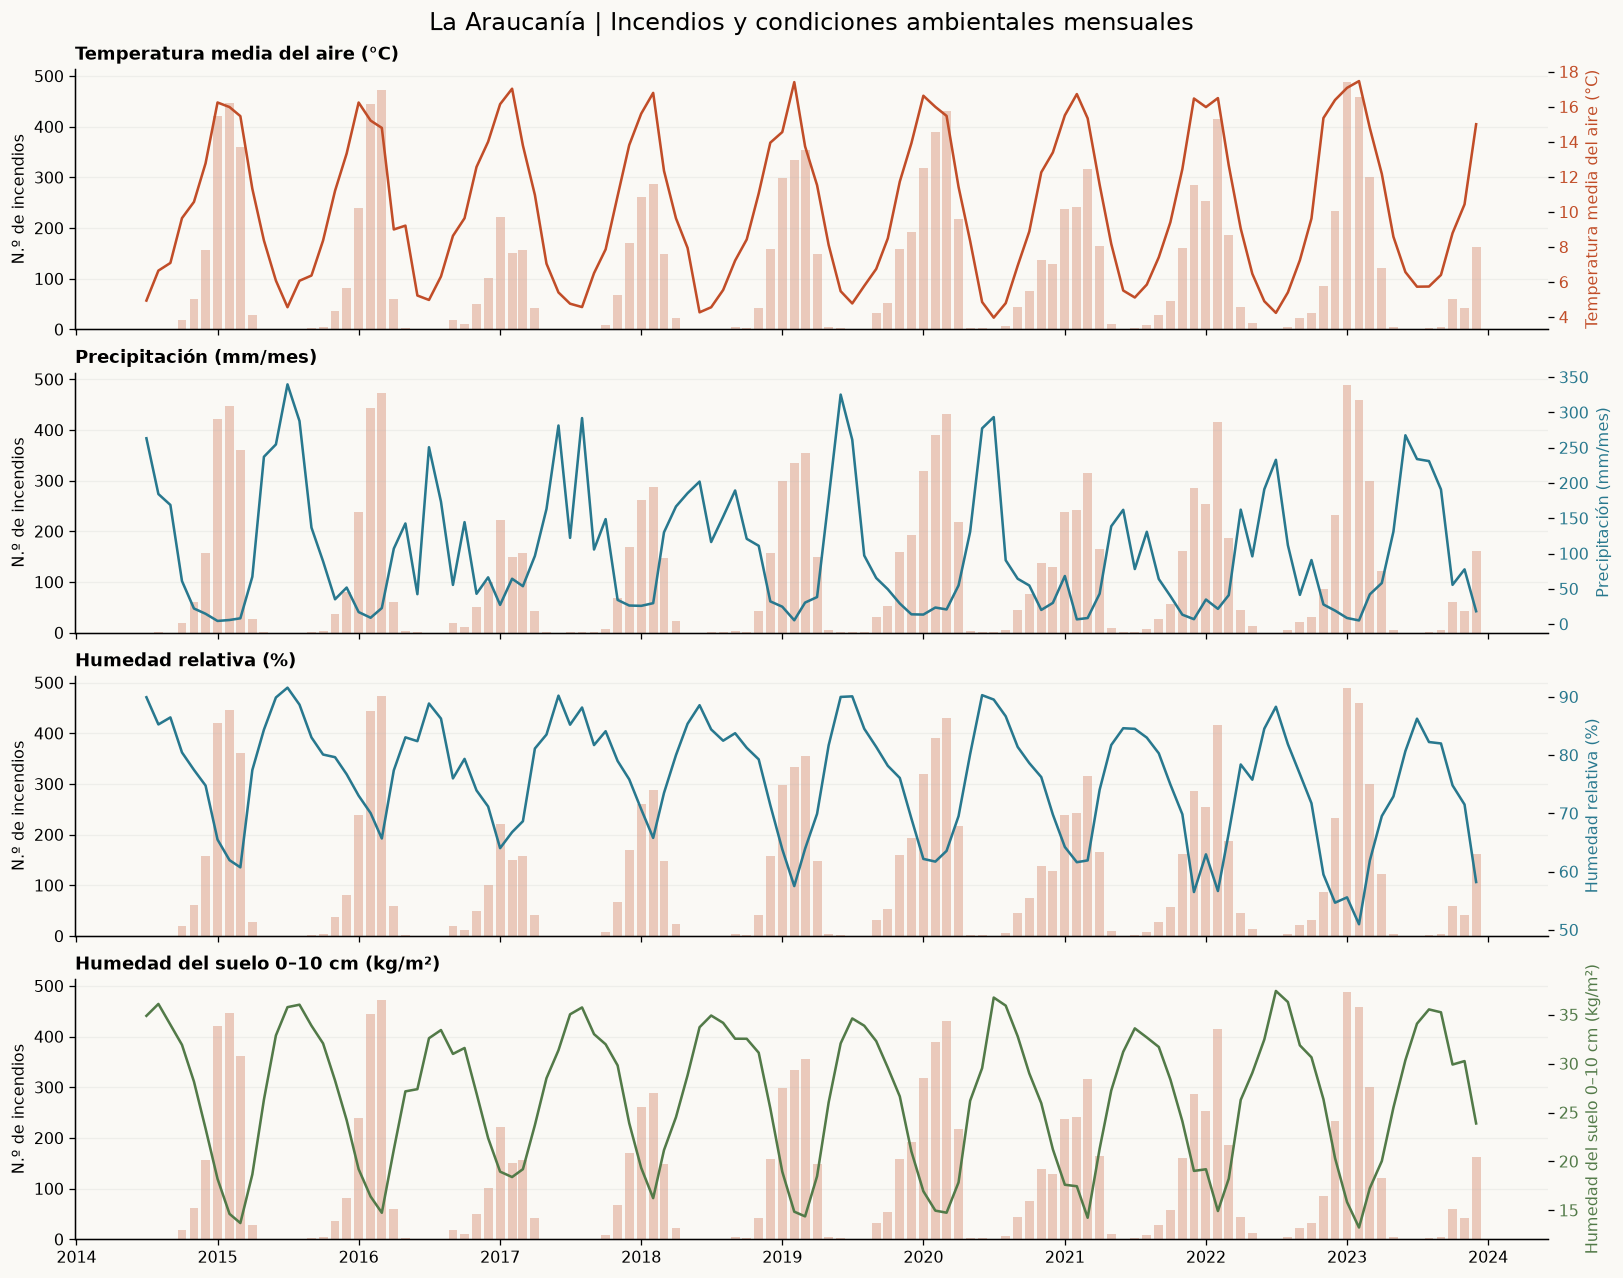

In [4]:
paneles = [
    ('temperature_2m_c', 'Temperatura media del aire (°C)', FUEGO),
    ('precipitation_mm', 'Precipitación (mm/mes)', AGUA),
    ('relative_humidity_2m_pct', 'Humedad relativa (%)', AGUA),
    ('soil_moisture_0_10cm_kgm2', 'Humedad del suelo 0–10 cm (kg/m²)', VERDE),
]
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True, layout='constrained')
for ax, (variable, etiqueta, color) in zip(axes, paneles):
    ax.bar(base_regional['month'], base_regional['numero_incendios'],
           width=23, color=FUEGO, alpha=0.28, label='Incendios')
    ax.set_ylabel('N.º de incendios')
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', alpha=0.15)
    otro = ax.twinx()
    otro.plot(base_regional['month'], base_regional[variable], color=color, lw=1.6)
    otro.set_ylabel(etiqueta, color=color)
    otro.tick_params(axis='y', labelcolor=color)
    ax.set_title(etiqueta, loc='left', fontsize=11)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('La Araucanía | Incendios y condiciones ambientales mensuales', fontsize=15)
plt.show()

## 4. Ciclo estacional compartido

Se calcula la media de cada mes del año y se estandarizan esas doce medias: `(media mensual − media de las 12 medias) / desviación estándar`. Esto compara la **forma del ciclo**, no las unidades ni su variabilidad interanual. La tabla informa cuántos años aporta cada mes; enero–junio tienen un año menos en la cobertura actual.

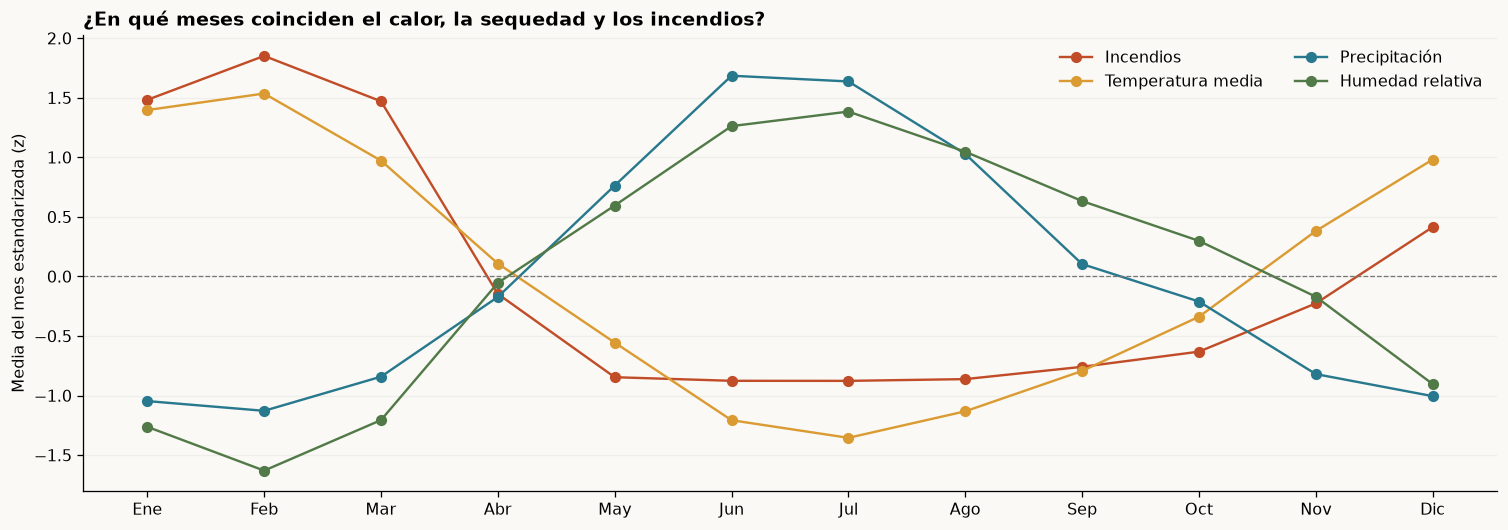

,Años disponibles,Incendios,Temperatura media,Precipitación,Humedad relativa
Enero,9,304.67,16.00,24.94,64.67
Febrero,9,352.22,16.57,19.03,61.45
Marzo,9,303.11,14.27,39.77,65.17
Abril,9,94.67,10.74,88.23,75.26
Mayo,9,4.56,8.03,155.91,80.96
Junio,9,0.67,5.37,222.64,86.80
Julio,10,0.60,4.76,219.17,87.87
Agosto,10,2.50,5.67,175.12,84.92
Septiembre,10,15.80,7.06,108.20,81.28
Octubre,10,32.20,8.91,85.44,78.35


In [5]:
variables_ciclo = {
    'numero_incendios': 'Incendios',
    'temperature_2m_c': 'Temperatura media',
    'precipitation_mm': 'Precipitación',
    'relative_humidity_2m_pct': 'Humedad relativa',
}
ciclo = base_regional.groupby('mes_numero')[list(variables_ciclo)].mean().reindex(range(1, 13))
ciclo_z = (ciclo - ciclo.mean()) / ciclo.std(ddof=0).replace(0, np.nan)
fig, ax = plt.subplots(figsize=(13, 4.5), layout='constrained')
for (variable, etiqueta), color in zip(
    variables_ciclo.items(), [FUEGO, '#db9b33', AGUA, VERDE]
):
    ax.plot(ciclo_z.index, ciclo_z[variable], marker='o', label=etiqueta, color=color)
ax.axhline(0, color='#777777', lw=0.8, ls='--')
ax.set_xticks(range(1, 13), [m[:3] for m in MESES])
ax.set_ylabel('Media del mes estandarizada (z)')
ax.set_title('¿En qué meses coinciden el calor, la sequedad y los incendios?', loc='left')
ax.legend(ncols=2, frameon=False)
ax.grid(axis='y', alpha=0.15)
plt.show()
resumen_ciclo = ciclo.rename(columns=variables_ciclo).round(2)
resumen_ciclo.insert(0, 'Años disponibles', base_regional.groupby('mes_numero').size())
resumen_ciclo.index = MESES
display(resumen_ciclo)

## 5. Calendarios comparativos: años excepcionales

El primer calendario muestra conteos reales. Los otros muestran **anomalías respecto de la media del mismo mes del año** dentro del período común: por ejemplo, un enero más cálido que los otros eneros. El gris señala meses fuera de la intersección, no ceros. La referencia es descriptiva y usa todo el período; no debe reutilizarse como preprocesamiento de un modelo sin separar entrenamiento y prueba.

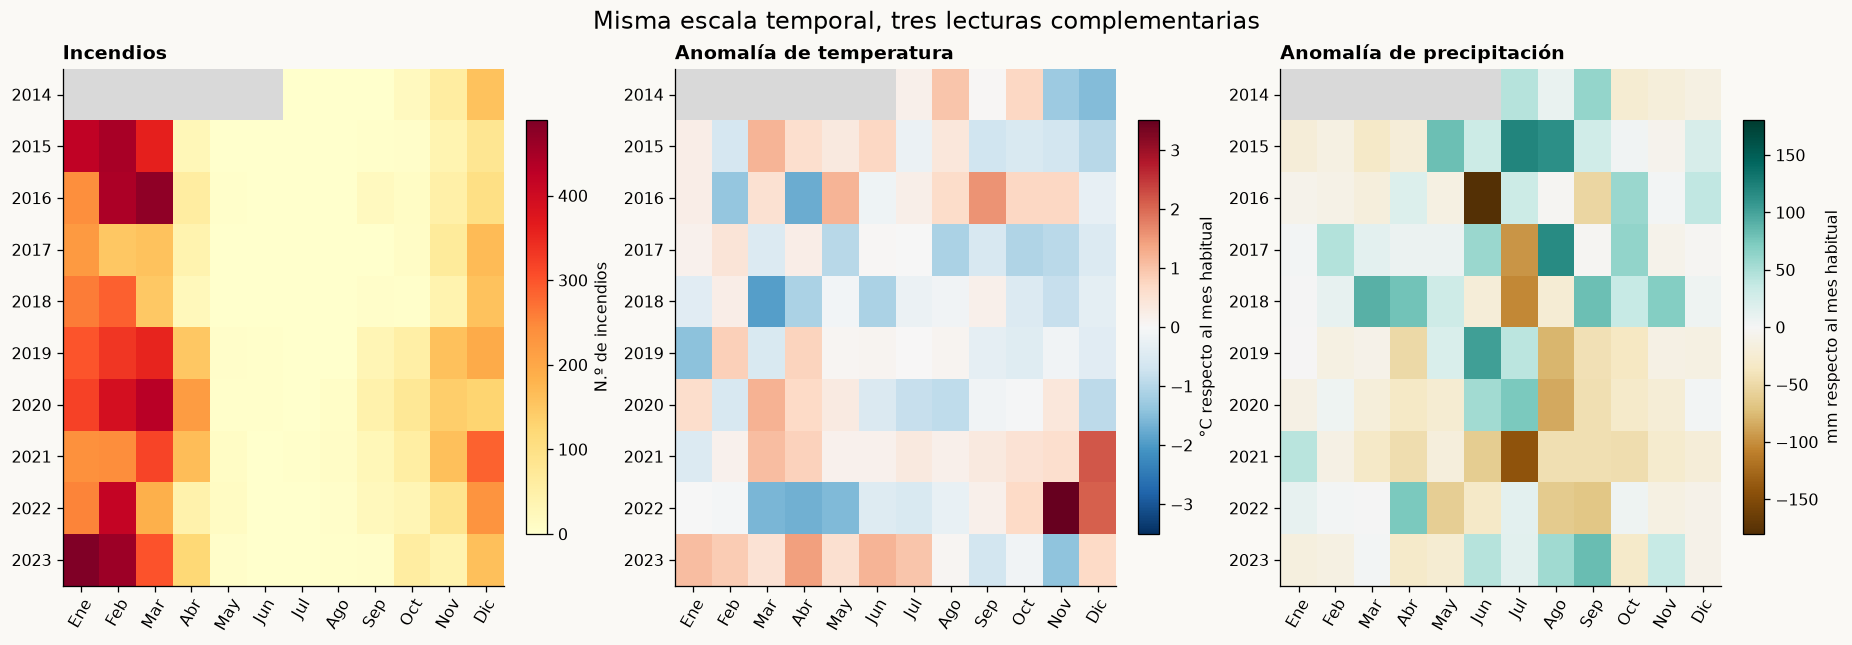

In [6]:
etiquetas = {
    'temperature_2m_c': 'Temperatura media del aire',
    'temperature_monthly_max_c': 'Temperatura máxima mensual',
    'relative_humidity_2m_pct': 'Humedad relativa',
    'precipitation_mm': 'Precipitación',
    'soil_moisture_0_10cm_kgm2': 'Humedad del suelo',
    'soil_temperature_0_10cm_c': 'Temperatura del suelo',
    'wind_speed_10m_ms': 'Velocidad del viento a 10 m',
    'aod_550': 'Espesor óptico de aerosoles (AOD)',
}
columnas_analisis = ['numero_incendios', *etiquetas]
assert base_regional[['numero_incendios', *[v for v in etiquetas if v not in VARIABLES_SUELO]]].notna().all().all()
assert base_regional.loc[~base_regional['soil_coverage_ok'], VARIABLES_SUELO].isna().all().all()
anomalias = base_regional[columnas_analisis] - (
    base_regional.groupby('mes_numero')[columnas_analisis].transform('mean')
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), layout='constrained')
mapas = [
    (base_regional['numero_incendios'], 'Incendios', 'N.º de incendios', 'YlOrRd', False),
    (anomalias['temperature_2m_c'], 'Anomalía de temperatura', '°C respecto al mes habitual', 'RdBu_r', True),
    (anomalias['precipitation_mm'], 'Anomalía de precipitación', 'mm respecto al mes habitual', 'BrBG', True),
]
for ax, (valores, titulo, unidad, paleta, divergente) in zip(axes, mapas):
    matriz = (base_regional.assign(valor=valores)
              .pivot(index='anio_calendario', columns='mes_numero', values='valor')
              .reindex(columns=range(1, 13)))
    cmap = plt.get_cmap(paleta).copy()
    cmap.set_bad('#d9d9d9')
    limite = np.nanmax(np.abs(matriz.to_numpy()))
    imagen = ax.imshow(matriz, aspect='auto', cmap=cmap,
                       vmin=-limite if divergente else 0, vmax=limite)
    ax.set_xticks(range(12), [m[:3] for m in MESES], rotation=60)
    ax.set_yticks(range(len(matriz)), matriz.index)
    ax.set_title(titulo, loc='left', fontsize=12)
    fig.colorbar(imagen, ax=ax, shrink=0.8, label=unidad)
fig.suptitle('Misma escala temporal, tres lecturas complementarias', fontsize=15)
plt.show()

## 6. Relaciones mensuales y estaciones del hemisferio sur

Cada punto es un mes regional. Los colores permiten reconocer si una relación se explica principalmente por el contraste verano–invierno. No se agrega una recta de regresión para no sugerir una relación lineal o causal sin contrastarla.

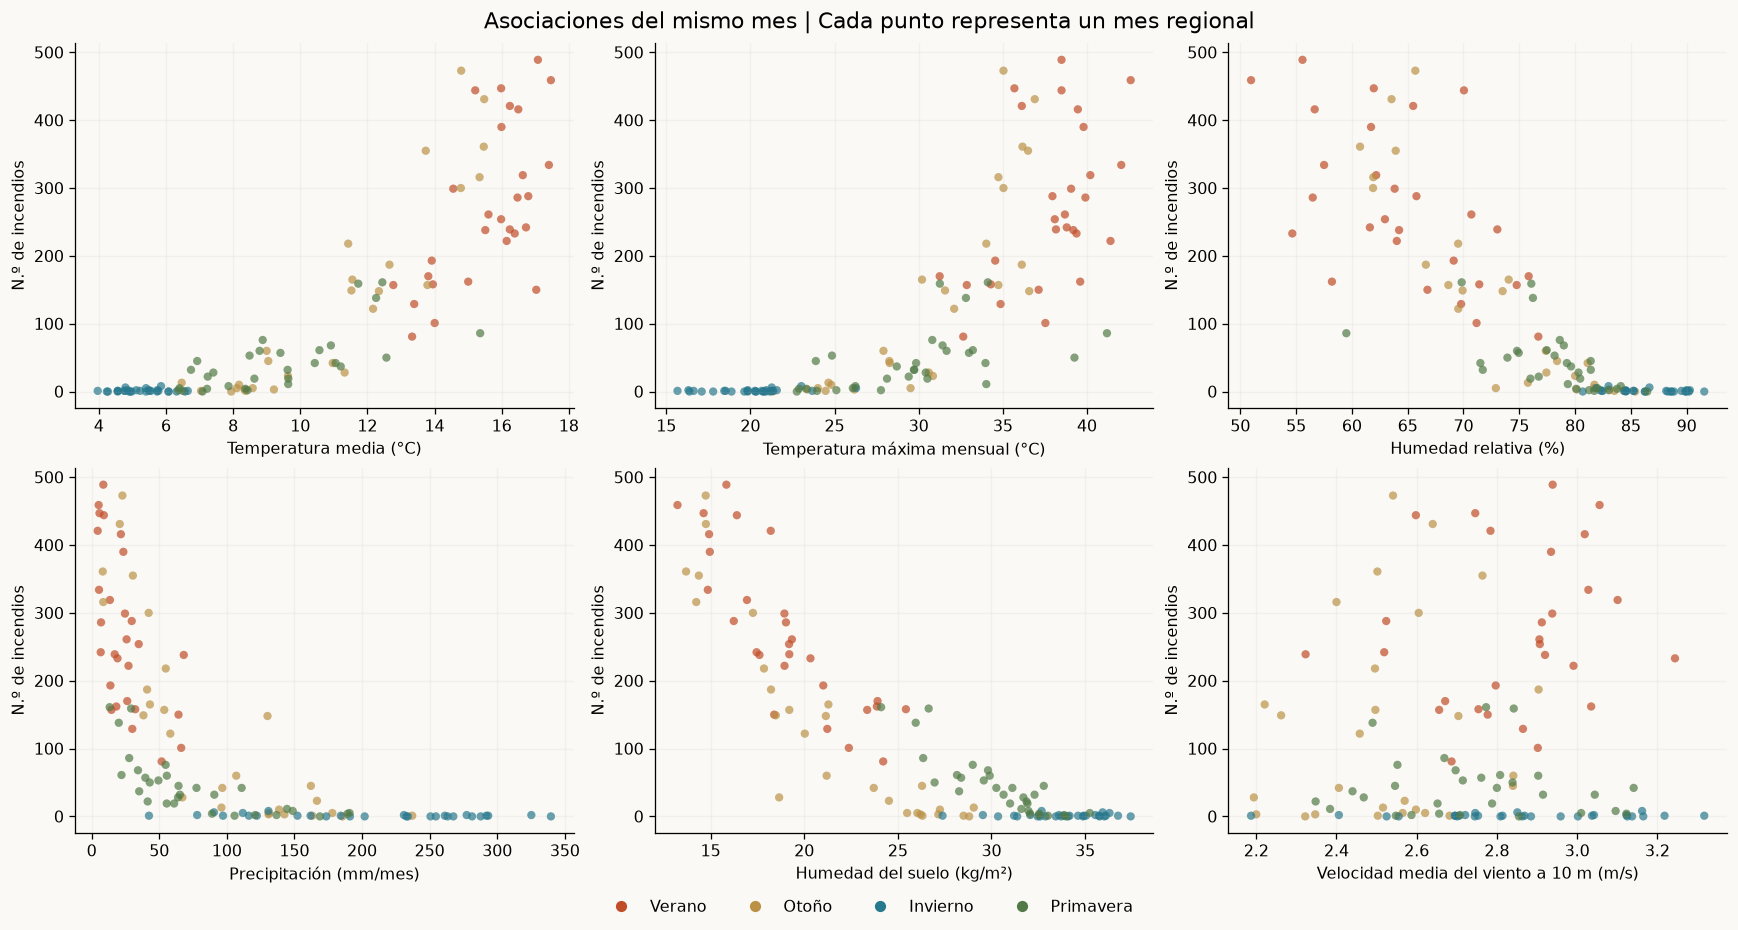

In [7]:
estacion_por_mes = {
    12: 'Verano', 1: 'Verano', 2: 'Verano',
    3: 'Otoño', 4: 'Otoño', 5: 'Otoño',
    6: 'Invierno', 7: 'Invierno', 8: 'Invierno',
    9: 'Primavera', 10: 'Primavera', 11: 'Primavera',
}
colores_estacion = {'Verano': FUEGO, 'Otoño': '#bb9146',
                    'Invierno': AGUA, 'Primavera': VERDE}
base_regional['estacion'] = base_regional['mes_numero'].map(estacion_por_mes)
variables_dispersion = [
    ('temperature_2m_c', 'Temperatura media (°C)'),
    ('temperature_monthly_max_c', 'Temperatura máxima mensual (°C)'),
    ('relative_humidity_2m_pct', 'Humedad relativa (%)'),
    ('precipitation_mm', 'Precipitación (mm/mes)'),
    ('soil_moisture_0_10cm_kgm2', 'Humedad del suelo (kg/m²)'),
    ('wind_speed_10m_ms', 'Velocidad media del viento a 10 m (m/s)'),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
for ax, (variable, etiqueta) in zip(axes.flat, variables_dispersion):
    for estacion, color in colores_estacion.items():
        parte = base_regional.loc[base_regional['estacion'].eq(estacion)]
        ax.scatter(parte[variable], parte['numero_incendios'],
                   s=27, color=color, alpha=0.7, edgecolors='none')
    ax.set_xlabel(etiqueta)
    ax.set_ylabel('N.º de incendios')
    ax.grid(alpha=0.12)
fig.legend(handles=[
    Line2D([], [], marker='o', linestyle='', color=color, label=estacion)
    for estacion, color in colores_estacion.items()
], loc='outside lower center', ncols=4, frameon=False)
fig.suptitle('Asociaciones del mismo mes | Cada punto representa un mes regional', fontsize=14)
plt.show()

## 7. Correlación observada frente a correlación de anomalías

Se compara Spearman sobre valores originales con Spearman sobre las desviaciones respecto de la media de cada mes. El segundo cálculo reduce el ciclo estacional medio, pero **no controla todos los factores de confusión ni la dependencia temporal**. No se presentan significancias estadísticas ni importancia predictiva.

AOD se incluye como comparación ambiental: puede capturar **humo generado por los propios incendios**. Una correlación alta no lo convierte en un predictor anticipado válido. Asimismo, el viento mensual no representa ráfagas extremas y las distintas temperaturas pueden aportar información redundante.

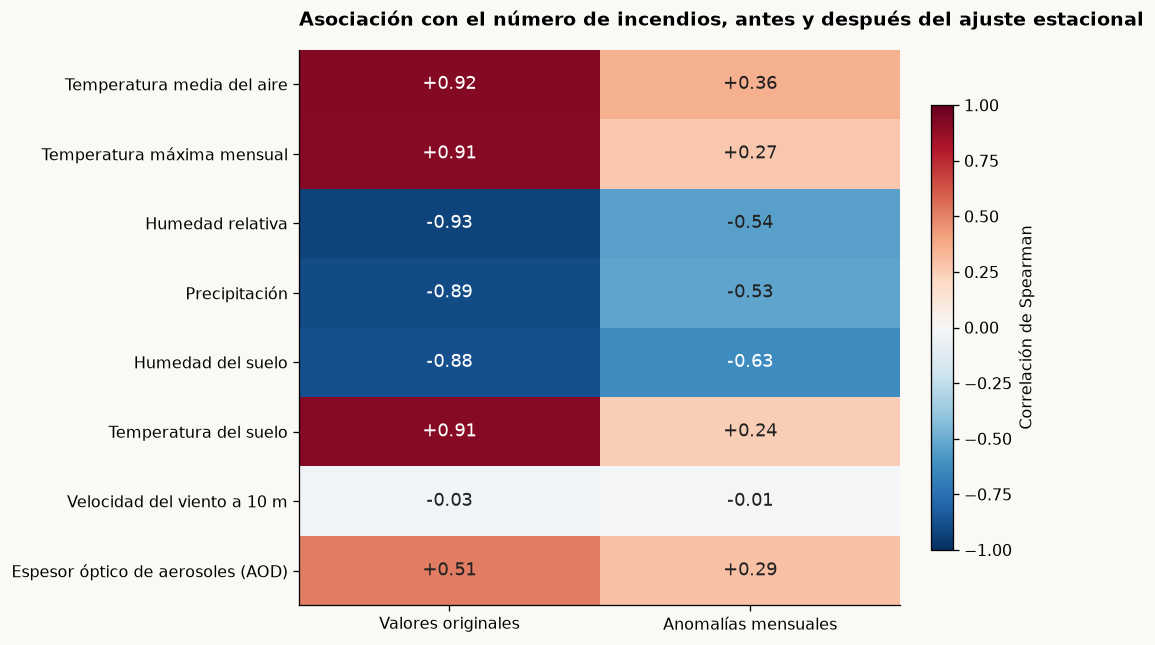

,Valores originales,Anomalías mensuales,Meses originales,Meses con anomalías
Temperatura media del aire,0.917,0.359,114,114
Temperatura máxima mensual,0.914,0.267,114,114
Humedad relativa,-0.926,-0.539,114,114
Precipitación,-0.894,-0.529,114,114
Humedad del suelo,-0.877,-0.630,114,114
Temperatura del suelo,0.910,0.244,114,114
Velocidad del viento a 10 m,-0.030,-0.008,114,114
Espesor óptico de aerosoles (AOD),0.513,0.293,114,114


In [8]:
# Spearman equivale a Pearson sobre rangos; no requiere scipy.
def correlacion_spearman(df, objetivo='numero_incendios'):
    return df.rank(method='average').corr(method='pearson')[objetivo].drop(objetivo)

correlaciones = pd.DataFrame({
    'Valores originales': correlacion_spearman(base_regional[columnas_analisis]),
    'Anomalías mensuales': correlacion_spearman(anomalias),
}).reindex(etiquetas)
fig, ax = plt.subplots(figsize=(9, 5.5), layout='constrained')
imagen = ax.imshow(correlaciones, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(2), correlaciones.columns)
ax.set_yticks(range(len(correlaciones)), [etiquetas[v] for v in correlaciones.index])
for fila in range(len(correlaciones)):
    for columna in range(2):
        valor = correlaciones.iloc[fila, columna]
        ax.text(columna, fila, f'{valor:+.2f}', ha='center', va='center',
                color='white' if abs(valor) > 0.6 else '#222222', fontsize=11)
ax.set_title('Asociación con el número de incendios, antes y después del ajuste estacional',
             loc='left', fontsize=12, pad=15)
fig.colorbar(imagen, ax=ax, label='Correlación de Spearman', shrink=0.8)
plt.show()
muestras_correlacion = pd.DataFrame({
    'Meses originales': [
        base_regional[['numero_incendios', v]].dropna().shape[0] for v in correlaciones.index
    ],
    'Meses con anomalías': [
        anomalias[['numero_incendios', v]].dropna().shape[0] for v in correlaciones.index
    ],
}, index=correlaciones.index)
display(correlaciones.join(muestras_correlacion).rename(index=etiquetas).round(3))

## 8. Preparación del cruce comuna–temporada

Se normalizan tildes, mayúsculas y espacios y se declara explícitamente el alias `CHOL CHOL → CHOLCHOL`. Las comunas se enlazan después mediante su código administrativo. No se usa coincidencia difusa: cualquier nombre desconocido detiene la ejecución.

Se suman las precipitaciones y se promedian temperatura, humedad y viento. Para la temperatura máxima se toma el máximo de los doce valores mensuales. Se excluyen temporadas con menos de doce meses ambientales: no se compara media temporada con un total anual.

**Suelo:** el promedio estacional se considera utilizable solo si los doce meses cumplen `soil_coverage_ok`. Se conserva `meses_suelo_validos` para auditarlo. Las temporadas de Saavedra permanecen en la base y sus incendios no se eliminan, pero su humedad de suelo analítica queda sin valor. Estos resúmenes describen lo ocurrido y **no estarían disponibles al inicio de la temporada** para predecir su total.

In [9]:
def normalizar_nombre(nombre):
    sin_tildes = ''.join(
        letra for letra in unicodedata.normalize('NFKD', nombre.upper().strip())
        if not unicodedata.combining(letra)
    )
    return ' '.join(sin_tildes.split())

catalogo = clima_comunas[['commune_id', 'commune_name']].drop_duplicates().copy()
catalogo['nombre_clave'] = catalogo['commune_name'].map(normalizar_nombre)
assert catalogo['nombre_clave'].is_unique
assert catalogo['commune_id'].is_unique
aliases = {'CHOL CHOL': 'CHOLCHOL'}
conaf_comunas = conaf_comunas.assign(
    nombre_clave=conaf_comunas['comuna'].map(normalizar_nombre).replace(aliases)
)
desconocidas = sorted(set(conaf_comunas['nombre_clave']) - set(catalogo['nombre_clave']))
assert not desconocidas, f'Revisar nombres sin correspondencia: {desconocidas}'
conaf_comunas = conaf_comunas.merge(catalogo, on='nombre_clave',
                                    how='left', validate='many_to_one')
assert not conaf_comunas.duplicated(['commune_id', 'temporada']).any()
assert conaf_comunas['numero_incendios'].ge(0).all()
display(conaf_comunas[['comuna', 'commune_name', 'commune_id']].drop_duplicates()
        .sort_values('commune_id').reset_index(drop=True))

,comuna,commune_name,commune_id
0,TEMUCO,Temuco,09101
1,CARAHUE,Carahue,09102
2,CUNCO,Cunco,09103
3,CURARREHUE,Curarrehue,09104
4,FREIRE,Freire,09105
5,GALVARINO,Galvarino,09106
6,GORBEA,Gorbea,09107
7,LAUTARO,Lautaro,09108
8,LONCOCHE,Loncoche,09109
9,MELIPEUCO,Melipeuco,09110


In [10]:
anio_inicio = clima_comunas['month'].dt.year - (clima_comunas['month'].dt.month <= 6).astype(int)
clima_comunas['temporada'] = anio_inicio.astype(str) + '-' + (anio_inicio + 1).astype(str)
clima_comunas_analisis['temporada'] = clima_comunas['temporada']
conteo_meses = clima_comunas.groupby(['commune_id', 'temporada'])['month'].nunique()
display(conteo_meses.unstack('commune_id').agg(['min', 'max'], axis=1)
        .rename(columns={'min': 'Mínimo de meses por comuna', 'max': 'Máximo de meses por comuna'}))

variables_estacionales = [
    'precipitation_mm', 'temperature_2m_c', 'temperature_monthly_max_c',
    'relative_humidity_2m_pct', 'soil_moisture_0_10cm_kgm2', 'wind_speed_10m_ms',
]
assert clima_comunas[variables_estacionales].notna().all().all(), (
    'Hay variables ambientales faltantes; revisar antes de agregar.'
)
clima_temporada = clima_comunas_analisis.groupby(['commune_id', 'temporada']).agg(
    meses_disponibles=('month', 'nunique'),
    meses_suelo_validos=('soil_coverage_ok', 'sum'),
    cobertura_minima_suelo_pct=('suelo_mensual_valid_area_pct', 'min'),
    precipitacion_total_mm=('precipitation_mm', 'sum'),
    temperatura_media_c=('temperature_2m_c', 'mean'),
    temperatura_maxima_c=('temperature_monthly_max_c', 'max'),
    humedad_relativa_pct=('relative_humidity_2m_pct', 'mean'),
    humedad_suelo_kgm2=('soil_moisture_0_10cm_kgm2', 'mean'),
    viento_medio_ms=('wind_speed_10m_ms', 'mean'),
).reset_index()
clima_temporada = clima_temporada.loc[clima_temporada['meses_disponibles'].eq(12)]
clima_temporada['humedad_suelo_kgm2'] = clima_temporada['humedad_suelo_kgm2'].where(
    clima_temporada['meses_suelo_validos'].eq(12)
)
cruce_comunal = clima_temporada.merge(
    conaf_comunas[['commune_id', 'temporada', 'commune_name', 'provincia', 'numero_incendios']],
    on=['commune_id', 'temporada'], how='left', validate='one_to_one', indicator=True,
)
assert cruce_comunal['_merge'].eq('both').all(), 'Hay temporadas climáticas completas sin objetivo CONAF.'
base_comunal = cruce_comunal.drop(columns='_merge').sort_values(['commune_id', 'temporada'])
n_comunas = catalogo['commune_id'].nunique()
assert base_comunal.groupby('temporada')['commune_id'].nunique().eq(n_comunas).all()
assert base_comunal.loc[base_comunal['meses_suelo_validos'].lt(12), 'humedad_suelo_kgm2'].isna().all()
assert base_comunal.loc[base_comunal['meses_suelo_validos'].eq(12), 'humedad_suelo_kgm2'].notna().all()
n_pares_suelo_validos = int(base_comunal['humedad_suelo_kgm2'].notna().sum())

# Validar que ambos productos de CONAF describen los mismos totales.
totales = base_comunal.groupby('temporada')['numero_incendios'].sum().to_frame('Suma comunal')
mensual_por_temporada = conaf_region.groupby('temporada').agg(
    total=('IX', 'sum'), meses=('month', 'nunique')
)
assert mensual_por_temporada.loc[totales.index, 'meses'].eq(12).all()
totales['Total regional'] = mensual_por_temporada['total']
totales['Diferencia'] = totales['Suma comunal'] - totales['Total regional']
assert totales['Diferencia'].eq(0).all(), 'Los totales de CONAF no coinciden.'
display(totales)
print(f'Cruce comunal: {len(base_comunal)} filas; {n_comunas} comunas y '
      f'{base_comunal.temporada.nunique()} temporadas completas.')
print(f'Comparaciones de suelo: {n_pares_suelo_validos} pares con 12 meses válidos; '
      f'{len(base_comunal) - n_pares_suelo_validos} omitidos solo para suelo.')
display(base_comunal.loc[base_comunal['meses_suelo_validos'].lt(12),
    ['commune_name', 'temporada', 'meses_suelo_validos', 'cobertura_minima_suelo_pct']])

,Mínimo de meses por comuna,Máximo de meses por comuna
temporada,,
2013-2014,6,6
2014-2015,12,12
2015-2016,12,12
2016-2017,12,12
2017-2018,12,12
2018-2019,12,12
2019-2020,12,12
2020-2021,12,12
2021-2022,12,12


,Suma comunal,Total regional,Diferencia
temporada,,,
2014-2015,1496.0,1496.0,0.0
2015-2016,1344.0,1344.0,0.0
2016-2017,753.0,753.0,0.0
2017-2018,969.0,969.0,0.0
2018-2019,1352.0,1352.0,0.0
2019-2020,1802.0,1802.0,0.0
2020-2021,1367.0,1367.0,0.0
2021-2022,1457.0,1457.0,0.0
2022-2023,1753.0,1753.0,0.0


Cruce comunal: 288 filas; 32 comunas y 9 temporadas completas.
Comparaciones de suelo: 279 pares con 12 meses válidos; 9 omitidos solo para suelo.


,commune_name,temporada,meses_suelo_validos,cobertura_minima_suelo_pct
135,Saavedra,2014-2015,0,36.49
136,Saavedra,2015-2016,0,36.49
137,Saavedra,2016-2017,0,36.49
138,Saavedra,2017-2018,0,36.49
139,Saavedra,2018-2019,0,36.49
140,Saavedra,2019-2020,0,36.49
141,Saavedra,2020-2021,0,36.49
142,Saavedra,2021-2022,0,36.49
143,Saavedra,2022-2023,0,36.49


## 9. ¿Qué comunas concentran más incendios y cómo cambian entre temporadas?

Las comunas se ordenan por su promedio de incendios en las temporadas comunes. Son **conteos absolutos**, no tasas de riesgo: no están normalizados por superficie, población ni cobertura forestal. Se usa un mapa de calor, no un mapa geográfico, porque los archivos no incluyen geometrías comunales.

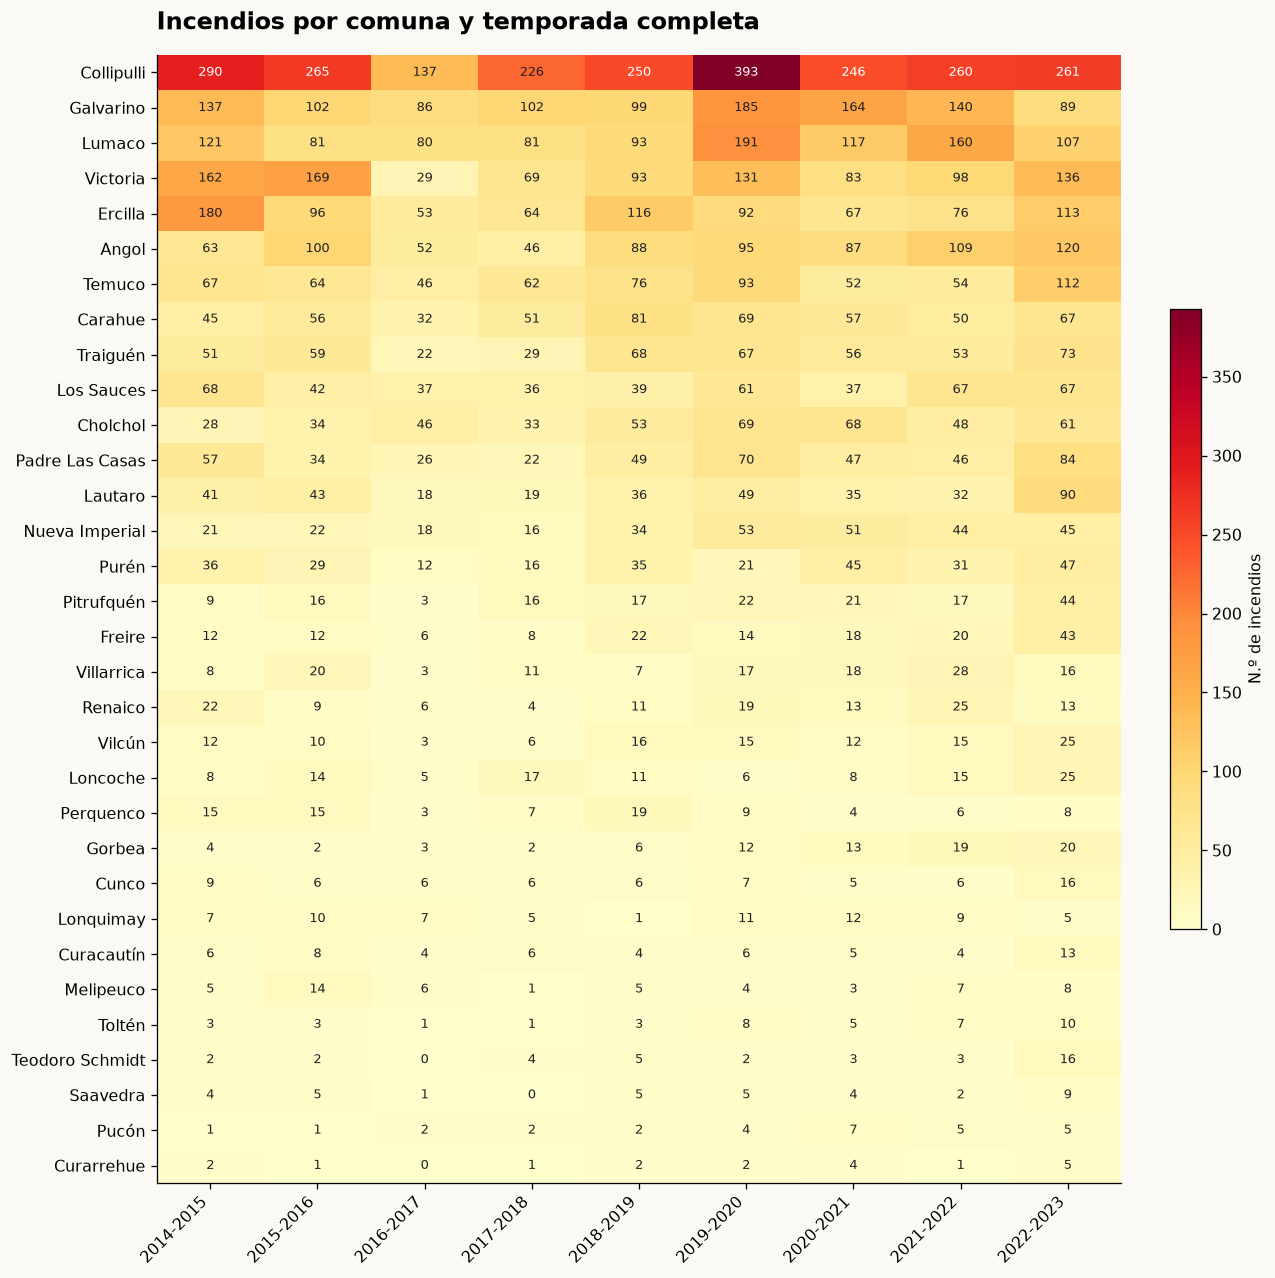

In [11]:
matriz_comunas = base_comunal.pivot(
    index='commune_name', columns='temporada', values='numero_incendios'
)
assert matriz_comunas.notna().all().all()
orden = matriz_comunas.mean(axis=1).sort_values(ascending=False).index
matriz_comunas = matriz_comunas.loc[orden]
fig, ax = plt.subplots(figsize=(11, 11), layout='constrained')
imagen = ax.imshow(matriz_comunas, aspect='auto', cmap='YlOrRd', vmin=0)
ax.set_yticks(range(len(matriz_comunas)), matriz_comunas.index)
ax.set_xticks(range(len(matriz_comunas.columns)), matriz_comunas.columns, rotation=45, ha='right')
for fila in range(len(matriz_comunas)):
    for columna in range(len(matriz_comunas.columns)):
        valor = matriz_comunas.iloc[fila, columna]
        ax.text(columna, fila, f'{valor:.0f}', ha='center', va='center', fontsize=8,
                color='white' if valor > matriz_comunas.to_numpy().max() * 0.6 else '#222222')
ax.set_title('Incendios por comuna y temporada completa', loc='left', fontsize=15, pad=16)
fig.colorbar(imagen, ax=ax, shrink=0.55, label='N.º de incendios')
plt.show()

## 10. Clima e incendios: diferencias territoriales frente a cambios dentro de cada comuna

Arriba: valores absolutos por comuna–temporada. Abajo: a cada valor se le resta el promedio de **esa comuna** entre las temporadas disponibles. Así se distingue una comuna habitualmente cálida y con muchos incendios de una temporada más cálida de lo habitual dentro de la misma comuna.

El centrado no controla cambios regionales de cada temporada ni demuestra causalidad. Los puntos comparten años y píxeles climáticos: las 288 filas no equivalen a 288 observaciones independientes. Los productos ambientales tienen resolución más gruesa que muchas comunas.

Los paneles indican su tamaño muestral: con los datos actuales, temperatura y precipitación conservan 288 pares; suelo utiliza **279 pares de 31 comunas**, omitiendo las nueve temporadas de Saavedra por baja cobertura. Los promedios para centrar el suelo se calculan solo sobre temporadas de suelo válidas.

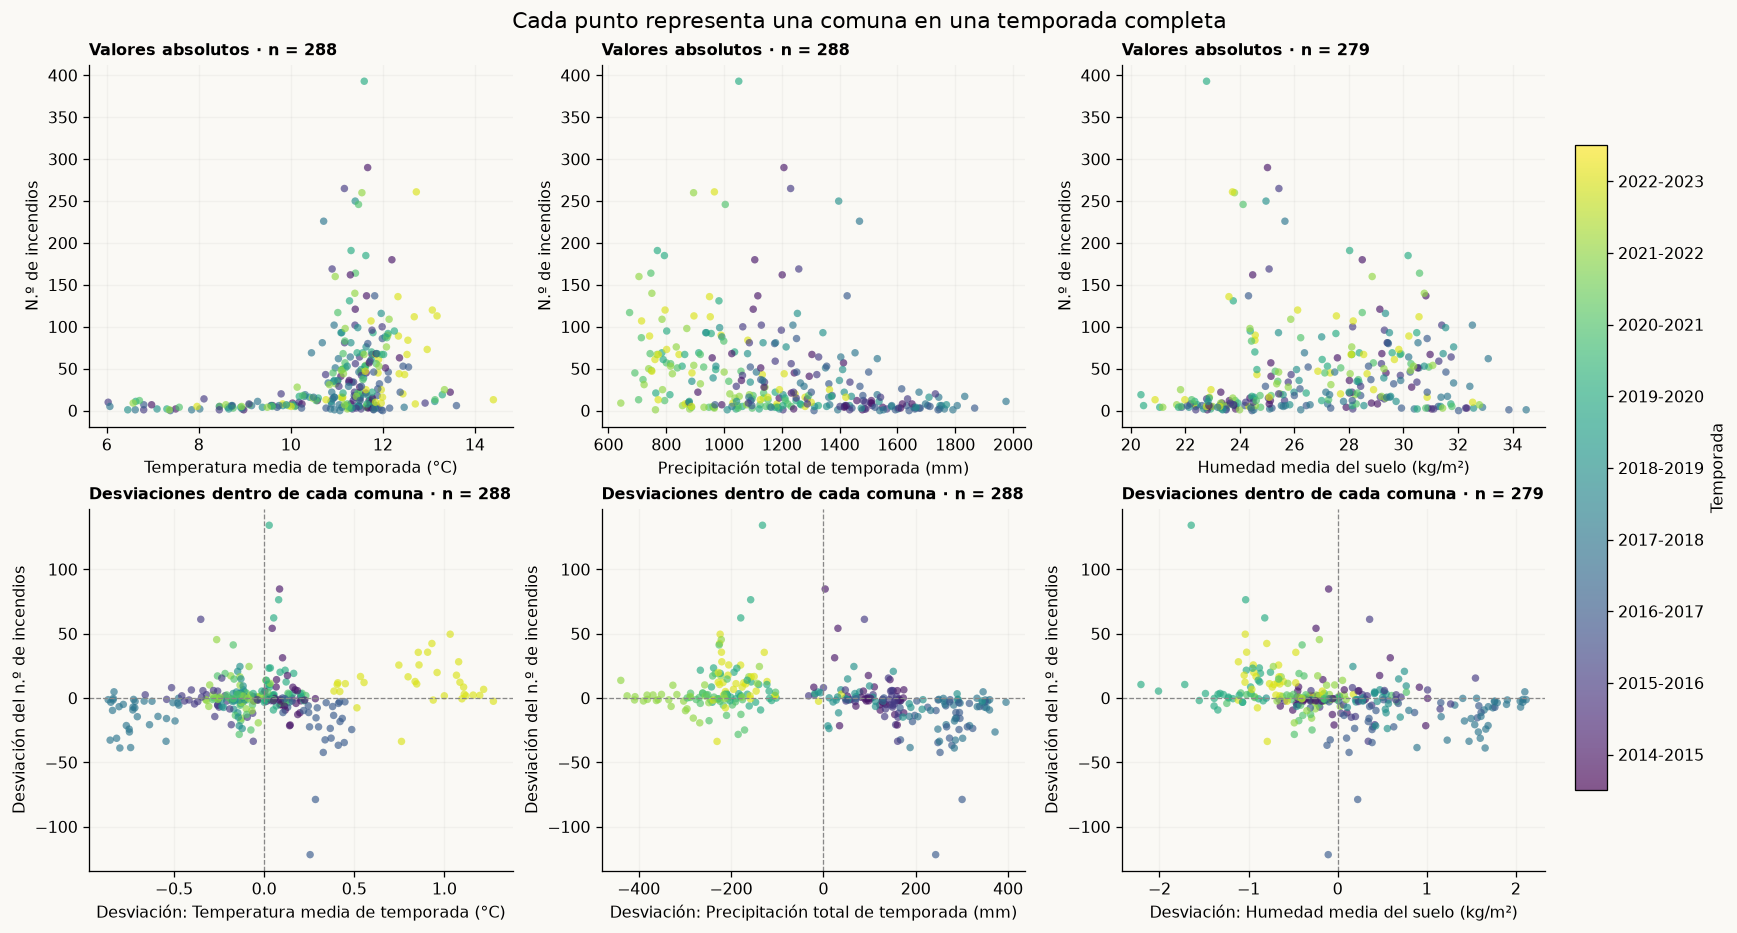

In [12]:
variables_comunales = [
    ('temperatura_media_c', 'Temperatura media de temporada (°C)'),
    ('precipitacion_total_mm', 'Precipitación total de temporada (mm)'),
    ('humedad_suelo_kgm2', 'Humedad media del suelo (kg/m²)'),
]
columnas_comunales = ['numero_incendios', *[v for v, _ in variables_comunales]]
desviaciones_comunales = base_comunal[columnas_comunales] - (
    base_comunal.groupby('commune_id')[columnas_comunales].transform('mean')
)
temporadas = sorted(base_comunal['temporada'].unique())
numero_temporada = base_comunal['temporada'].map({t: i for i, t in enumerate(temporadas)})
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
for columna, (variable, etiqueta) in enumerate(variables_comunales):
    for fila, df in enumerate([base_comunal, desviaciones_comunales]):
        ax = axes[fila, columna]
        validos = df[[variable, 'numero_incendios']].notna().all(axis=1)
        puntos = ax.scatter(df.loc[validos, variable], df.loc[validos, 'numero_incendios'],
                            c=numero_temporada.loc[validos],
                            cmap='viridis', vmin=-0.5, vmax=len(temporadas) - 0.5,
                            s=22, alpha=0.65, edgecolors='none')
        ax.set_xlabel(etiqueta if fila == 0 else 'Desviación: ' + etiqueta)
        ax.set_ylabel('N.º de incendios' if fila == 0 else 'Desviación del n.º de incendios')
        titulo = 'Valores absolutos' if fila == 0 else 'Desviaciones dentro de cada comuna'
        ax.set_title(f'{titulo} · n = {int(validos.sum())}', loc='left', fontsize=10)
        ax.grid(alpha=0.12)
        if fila == 1:
            ax.axhline(0, lw=0.8, color='#888888', ls='--')
            ax.axvline(0, lw=0.8, color='#888888', ls='--')
barra = fig.colorbar(puntos, ax=axes, shrink=0.8, pad=0.02, label='Temporada')
barra.set_ticks(range(len(temporadas)), labels=temporadas)
fig.suptitle('Cada punto representa una comuna en una temporada completa', fontsize=14)
plt.show()

## 11. Resumen reproducible y límites de interpretación

La siguiente síntesis se calcula con los archivos cargados; no contiene un ranking fijo ni se presenta como evaluación de predicción.

In [13]:
pico = base_regional.loc[base_regional['numero_incendios'].idxmax()]
media_comunas = base_comunal.groupby('commune_name')['numero_incendios'].mean().sort_values(ascending=False)
# AOD se omite de esta selección porque puede ser una consecuencia del fuego.
ambientales = correlaciones.drop(index='aod_550')
variable_original = ambientales['Valores originales'].abs().idxmax()
variable_anomalia = ambientales['Anomalías mensuales'].abs().idxmax()
display(Markdown(
    f'- **Cobertura regional:** {len(base_regional)} meses, '
    f'{base_regional.month.min():%Y-%m} a {base_regional.month.max():%Y-%m}.\n'
    f'- **Cobertura comunal:** {len(base_comunal)} pares comuna–temporada, '
    f'{n_comunas} comunas y {len(temporadas)} temporadas completas.\n'
    f'- **Calidad del suelo comunal:** {n_pares_suelo_validos} pares utilizables; '
    f'{len(base_comunal) - n_pares_suelo_validos} omitidos solo en suelo '
    f'(umbral mensual: {UMBRAL_SUELO:g} %, 12 meses válidos por temporada).\n'
    f'- **Mayor conteo mensual regional:** {pico.numero_incendios:.0f} incendios en {pico.month:%Y-%m}.\n'
    f'- **Mayor promedio comunal:** {media_comunas.index[0]}, '
    f'{media_comunas.iloc[0]:.1f} incendios por temporada (conteo absoluto).\n'
    f'- **Mayor asociación absoluta original, sin AOD:** {etiquetas[variable_original]}, '
    f'ρ = {ambientales.loc[variable_original, "Valores originales"]:+.3f}.\n'
    f'- **Mayor asociación absoluta entre anomalías, sin AOD:** {etiquetas[variable_anomalia]}, '
    f'ρ = {ambientales.loc[variable_anomalia, "Anomalías mensuales"]:+.3f}.'
))

- **Cobertura regional:** 114 meses, 2014-07 a 2023-12.
- **Cobertura comunal:** 288 pares comuna–temporada, 32 comunas y 9 temporadas completas.
- **Calidad del suelo comunal:** 279 pares utilizables; 9 omitidos solo en suelo (umbral mensual: 80 %, 12 meses válidos por temporada).
- **Mayor conteo mensual regional:** 489 incendios en 2023-01.
- **Mayor promedio comunal:** Collipulli, 258.7 incendios por temporada (conteo absoluto).
- **Mayor asociación absoluta original, sin AOD:** Humedad relativa, ρ = -0.926.
- **Mayor asociación absoluta entre anomalías, sin AOD:** Humedad del suelo, ρ = -0.630.

### Qué permite concluir y qué falta para predecir

- **Asociación no es causalidad ni importancia predictiva.** Comparar las columnas original/anomalías ayuda a reconocer cuánto aporta el ciclo estacional. No hay evaluación de un modelo en este notebook.
- Para anticipar incendios, usar variables disponibles al emitir el pronóstico: rezagos, lluvia acumulada previa o pronósticos meteorológicos. No usar el clima observado completo del mes o temporada que se intenta predecir.
- Validar por bloques temporales, nunca repartiendo meses o comunas aleatoriamente. Calcular medias de referencia, escalas y selección de variables solo con entrenamiento.
- Las medias mensuales ocultan olas de calor y ráfagas; la temperatura máxima de un píxel no es una media comunal. El archivo distingue `temperature_monthly_max_c` de `temperature_monthly_peak_area_mean_c`.
- Se consumen exclusivamente los CSV mensuales de `limpios/` y su reporte; no se ejecuta nuevamente la limpieza ni se borran extremos. `soil_coverage_ok` se usa para excluir únicamente mediciones de suelo de baja cobertura, sin imputarlas ni descartar los incendios de esas comunas.
- La geografía ambiental usa límites administrativos de referencia fija (2024); no reconstruye cambios históricos. Consultar `datos_mensuales_2014_2023/metadatos.json` para productos, resolución y agregaciones, y `datos_mensuales_2014_2023/limpios/reporte_validacion.json` para las unidades corregidas, el umbral y las decisiones de limpieza.
- No se incorpora la red vial de 2019 como si variara anualmente: es una referencia cartográfica estática y se desconocen las fechas de construcción.
- Para estudiar riesgo territorial, complementar con superficie forestal, uso del suelo, población y exposición humana. Los conteos no son probabilidades ni medidas de gravedad.

**Bases disponibles para continuar:** `base_regional`, `base_comunal`, `anomalias` y `correlaciones`. No se exportan archivos ni se alteran las fuentes automáticamente.